In [564]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor
from wordcloud import WordCloud
from sklearn.datasets import fetch_olivetti_faces
from tensorflow.keras.datasets import cifar10
from sklearn.decomposition import PCA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

plt.rcParams['axes.unicode_minus'] = False

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

In [565]:
df = pd.read_csv('./ch14_flight_delay.csv')

In [566]:
df

,flight_id,flight_date,airline,departure_airport,arrival_airport,scheduled_hour,day_of_week,distance_km,temperature_c,wind_speed_kmh,precipitation_mm,visibility_km,airport_congestion,previous_flight_delay_min,aircraft_age_years,passenger_load_pct,holiday,weather_condition,delay_minutes
0,FL202500768,2025/09/08,Jeju Air,pus,ICN,16,0,406.4,12.2,16.5,0.0,12.4,0.572,14.3,12.7,72.0,0,Clear,24.9
1,FL202505880,2025-05-15,Asiana Airlines,KWJ,ICN,7,3,336.2,23.9,19.4,0.0,16.3,0.442,12.3,1.5,64.4,0,Clear,10.0
2,FL202508460,2025-02-25,Asiana Airlines,ICN,USN,20,1,366.8,-1.5°C,3.2,0.0,5.4,0.502,2.1,3.7,88.2,0,Clear,1.0
3,FL202506025,2025-09-22,Jeju Air,KWJ,GMP,22,0,359.9,23.3,20.9,4.9,4.3,0.295,6.8,8.0,75.2,0,Rain,24.9
4,FL202501987,2025-04-21,Jin Air,ICN,USN,10,0,369.5,8.9,8.5,0.0,16.4,0.826,22.2,12.5,93.3,0,Clear,39.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,FL202505332,2025-01-10,T'way Air,USN,ICN,7,4,406.5,0.7,5.9,0.0,14.9,0.362,12.5,11.6,84.7,0,NaN,23.5
9996,FL202507495,2025-10-01,Jeju Air,CJU,GMP,17,2,538.1,9.9,4.9,0.0,16.4,0.963,39.8,12.6,98.6,No,Clear,46.0
9997,FL202509278,2025-08-08,T'way Air,rsu,GMP,23,4,381.3,20.8,18.2,0.0,18.5,0.160,29.4,5.7,75.2,0,Clear,30.0
9998,FL202509000,2025-10-26,TWAY AIR,KWJ,PUS,10,6,339.9,4.2,22.3,0.0,15.0,0.546,9.5,10.5,91.8,1,Cloudy,23.2


In [567]:
print(df.duplicated().sum())

150


In [568]:
df = df.drop_duplicates()
print(df.duplicated().sum())

0


In [569]:
df.isna().sum()

flight_id                      0
flight_date                    0
airline                       78
departure_airport              0
arrival_airport                0
scheduled_hour                 0
day_of_week                    0
distance_km                    0
temperature_c                294
wind_speed_kmh               214
precipitation_mm             177
visibility_km                245
airport_congestion           146
previous_flight_delay_min    295
aircraft_age_years           117
passenger_load_pct           197
holiday                        0
weather_condition            118
delay_minutes                 28
dtype: int64

In [570]:
df['airline'].value_counts()

airline
Asiana Airlines      1412
Jin Air              1391
T'way Air            1353
Jeju Air             1352
Air Busan            1335
Korean Air           1324
제주항공                   72
진에어                    71
AIR BUSAN              64
JEJU AIR               63
 Asiana Airlines       62
jin air                60
ASIANA                 59
JinAir                 59
 Jeju Air              59
 Jin Air               58
아시아나                   56
에어부산                   53
 T'way Air             52
korean air             52
TWAY AIR               52
jeju air               52
Asiana                 51
KoreanAir              51
air busan              51
t'way air              50
KOREAN AIR             50
 Korean Air            49
 Air Busan             48
티웨이                    47
JIN AIR                46
Tway Air               45
JejuAir                45
대한항공                   44
asiana airlines        44
AirBusan               40
Name: count, dtype: int64

In [571]:
def standardize_airline(name):
    if pd.isna(name):
        return name
    
    # 소문자 변환 및 양쪽 공백 제거
    clean_name = str(name).strip().lower()
    
    if 'asiana' in clean_name or '아시아나' in clean_name:
        return 'Asiana Airlines'
    elif 'jin' in clean_name or '진에어' in clean_name:
        return 'Jin Air'
    elif 'jeju' in clean_name or '제주' in clean_name:
        return 'Jeju Air'
    elif 'tway' in clean_name or "t'way" in clean_name or '티웨이' in clean_name:
        return "Tway Air"
    elif 'busan' in clean_name or '에어부산' in clean_name:
        return 'Air Busan'
    elif 'korean' in clean_name or '대한' in clean_name:
        return 'Korean Air'
    else:
        return name # 정의되지 않은 기타 항공사는 원본 유지

# airline 컬럼 전체에 적용
df['airline'] = df['airline'].apply(standardize_airline)

In [572]:
df['airline'].value_counts()

airline
Jin Air            1685
Asiana Airlines    1684
Jeju Air           1643
Tway Air           1599
Air Busan          1591
Korean Air         1570
Name: count, dtype: int64

In [573]:
df = df.dropna(subset=['airline'])

In [574]:
# 타겟 값은 임의로 채우면 문제가 될 수 있어서 드랍
df = df.dropna(subset=['delay_minutes'])

In [575]:
df.isna().sum()

flight_id                      0
flight_date                    0
airline                        0
departure_airport              0
arrival_airport                0
scheduled_hour                 0
day_of_week                    0
distance_km                    0
temperature_c                291
wind_speed_kmh               211
precipitation_mm             175
visibility_km                243
airport_congestion           144
previous_flight_delay_min    293
aircraft_age_years           116
passenger_load_pct           196
holiday                        0
weather_condition            117
delay_minutes                  0
dtype: int64

In [576]:
df.count()

flight_id                    9744
flight_date                  9744
airline                      9744
departure_airport            9744
arrival_airport              9744
scheduled_hour               9744
day_of_week                  9744
distance_km                  9744
temperature_c                9453
wind_speed_kmh               9533
precipitation_mm             9569
visibility_km                9501
airport_congestion           9600
previous_flight_delay_min    9451
aircraft_age_years           9628
passenger_load_pct           9548
holiday                      9744
weather_condition            9627
delay_minutes                9744
dtype: int64

In [577]:
df['weather_condition'].value_counts()

weather_condition
Clear         3497
Cloudy        2265
Rain          1147
Fog            750
Heavy Rain     525
Snow           249
 Clear         151
clear          126
SUNNY          124
맑음             114
 Cloudy         83
cloudy          79
흐림              75
CLOUD           75
rain            48
RAINY           44
 Rain           43
비               38
FOGGY           34
안개              32
fog             31
HeavyRain       21
폭우              19
HEAVY_RAIN      18
heavy rain      16
snow            10
SNOWY            9
눈                4
Name: count, dtype: int64

In [578]:
def standardize_weather(condition):
    if pd.isna(condition):
        return condition

    clean = str(condition).strip().lower().replace('_', ' ')
    
    if 'heavy' in clean or '호우' in clean or '폭우' in clean:
        return 'Heavy Rain'
    
    elif 'rain' in clean or '비' in clean:
        return 'Rain'
    
    elif 'clear' in clean or 'sunny' in clean or '맑음' in clean or 'sun' in clean:
        return 'Clear'
    
    elif 'cloud' in clean or '흐림' in clean or 'overcast' in clean:
        return 'Cloudy'
    
    elif 'fog' in clean or '안개' in clean or 'mist' in clean or 'haze' in clean:
        return 'Fog'
    
    elif 'snow' in clean or '눈' in clean:
        return 'Snow'
    
    elif 'unknown' in clean or '미상' in clean:
        return 'Unknown'
    
    else:
        return condition

# weather_condition 컬럼에 적용
df['weather_condition'] = df['weather_condition'].apply(standardize_weather)


In [579]:
df['weather_condition'].value_counts()

weather_condition
Clear         4012
Cloudy        2577
Rain          1320
Fog            847
Heavy Rain     599
Snow           272
Name: count, dtype: int64

In [580]:
df.dtypes

flight_id                     object
flight_date                   object
airline                       object
departure_airport             object
arrival_airport               object
scheduled_hour                object
day_of_week                    int64
distance_km                   object
temperature_c                 object
wind_speed_kmh                object
precipitation_mm             float64
visibility_km                float64
airport_congestion           float64
previous_flight_delay_min    float64
aircraft_age_years           float64
passenger_load_pct            object
holiday                       object
weather_condition             object
delay_minutes                float64
dtype: object

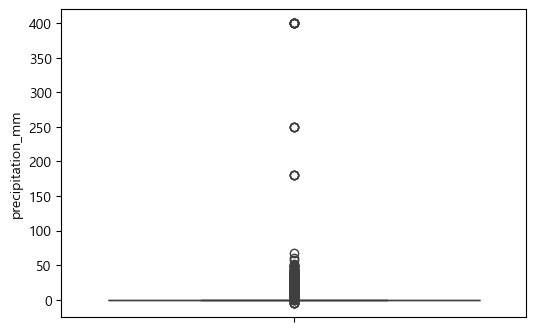

In [581]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['precipitation_mm'])
plt.show()

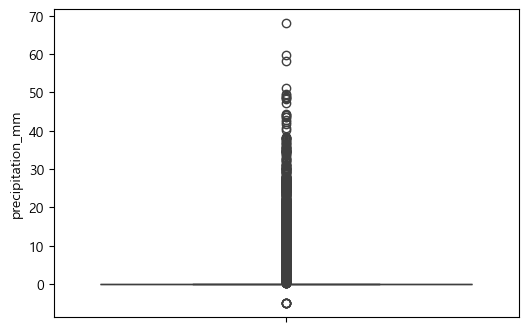

In [582]:
df = df[(df['precipitation_mm'] <= 100) | (df['precipitation_mm'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['precipitation_mm'])
plt.show()

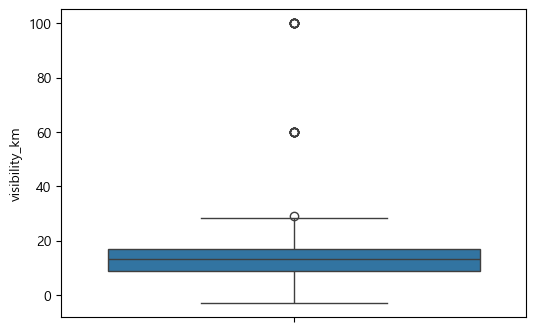

In [583]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['visibility_km'])
plt.show()

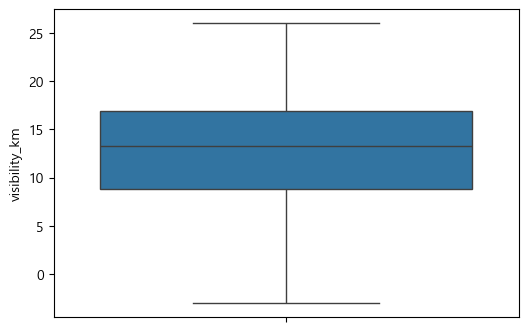

In [584]:
df = df[(df['visibility_km'] <= 26) | (df['visibility_km'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['visibility_km'])
plt.show()

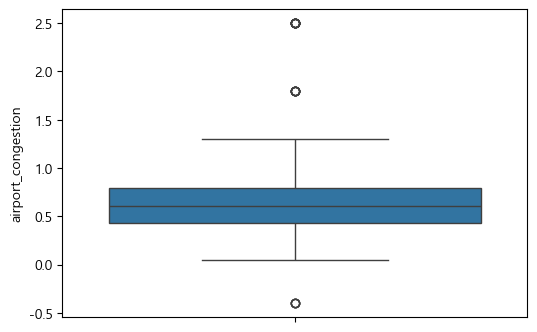

In [585]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['airport_congestion'])
plt.show()

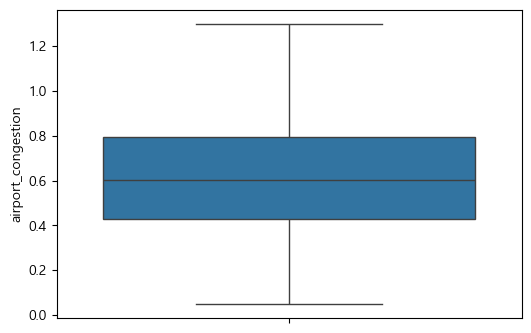

In [586]:
df = df[(df['airport_congestion'] <= 1.5) | (df['airport_congestion'].isna())]
df = df[(df['airport_congestion'] >= 0) | (df['airport_congestion'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['airport_congestion'])
plt.show()

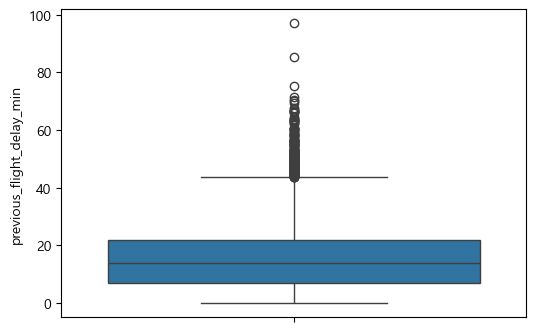

In [587]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['previous_flight_delay_min'])
plt.show()

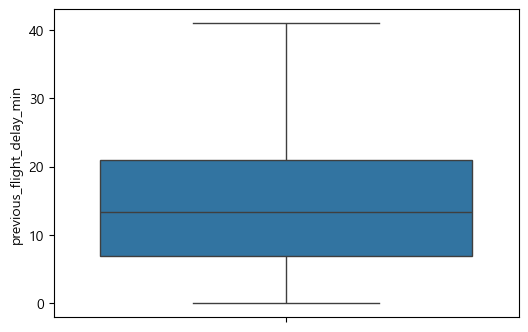

In [588]:
df = df[(df['previous_flight_delay_min'] <= 41) | (df['previous_flight_delay_min'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['previous_flight_delay_min'])
plt.show()

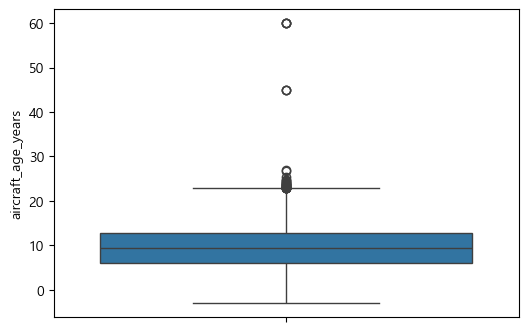

In [589]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['aircraft_age_years'])
plt.show()

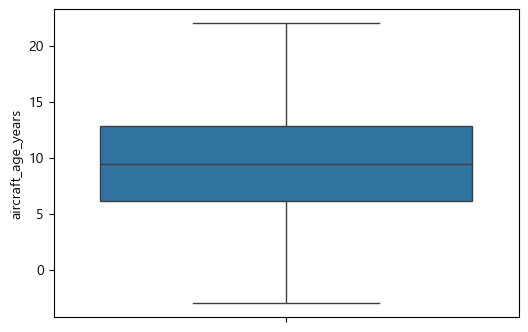

In [590]:
df = df[(df['aircraft_age_years'] <= 22) | (df['aircraft_age_years'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['aircraft_age_years'])
plt.show()

In [591]:
df['distance_km'] = (
    df['distance_km']
    .astype(str)
    .str.replace('km', '', case=False, regex=False)
    .str.strip()
)

df['distance_km'] = pd.to_numeric(df['distance_km'], errors='coerce')
df['scheduled_hour'] = df['scheduled_hour'].astype(str).str.split(':').str[0]
df['scheduled_hour'] = pd.to_numeric(df['scheduled_hour'], errors='coerce').fillna(0).astype(int)

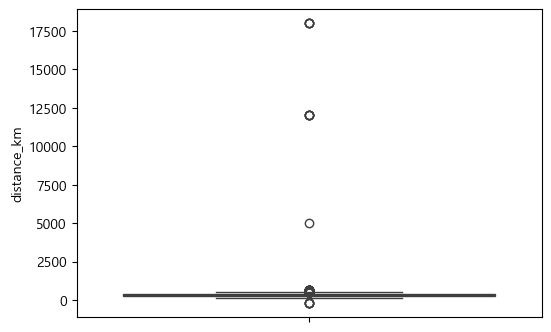

In [592]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['distance_km'])
plt.show()

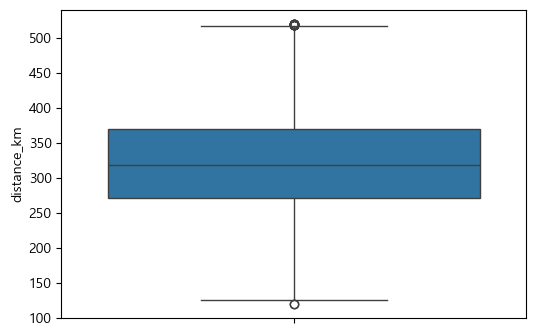

In [593]:
df = df[(df['distance_km'] <= 520)|(df['distance_km'].isna())]
df = df[(df['distance_km'] >= 0)|(df['distance_km'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['distance_km'])
plt.show()

In [594]:
weather_num_cols = ['temperature_c', 'wind_speed_kmh', 'precipitation_mm', 'visibility_km']
for col in weather_num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

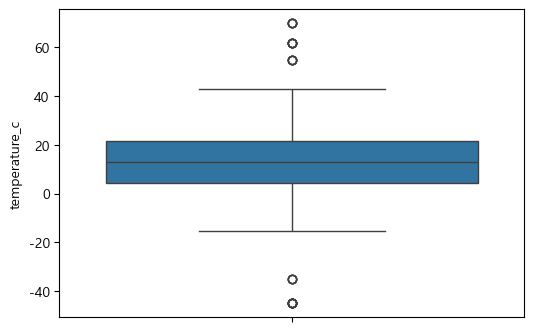

In [595]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['temperature_c'])
plt.show()
df = df[(df['temperature_c'] <= 40)|(df['temperature_c'].isna())]
df = df[(df['temperature_c'] >= -20)|(df['temperature_c'].isna())]

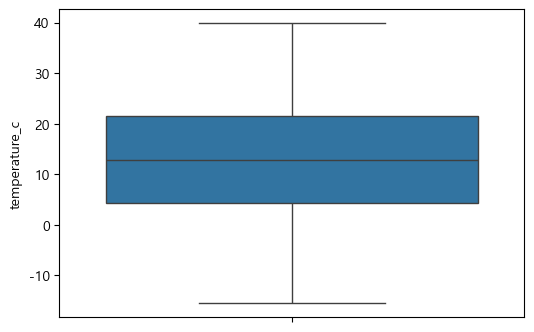

In [596]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['temperature_c'])
plt.show()

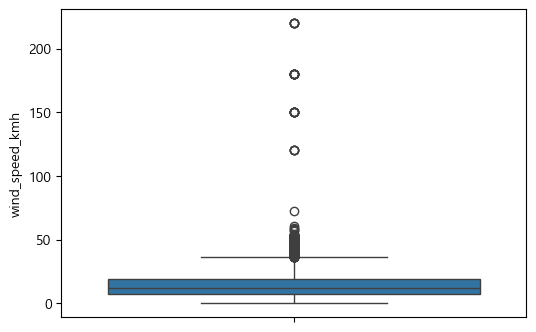

In [597]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['wind_speed_kmh'])
plt.show()
df = df[(df['wind_speed_kmh'] <= 33)|(df['wind_speed_kmh'].isna())]

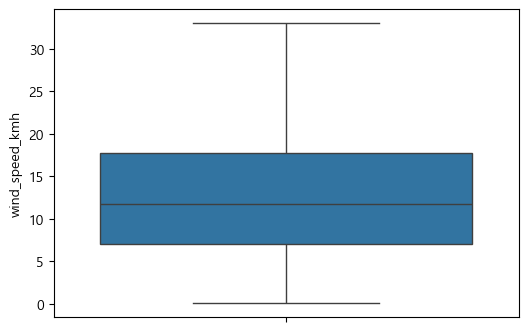

In [598]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['wind_speed_kmh'])
plt.show()

In [599]:
if df['passenger_load_pct'].dtype == 'object':
    df['passenger_load_pct'] = df['passenger_load_pct'].astype(str).str.replace('%', '')

df['passenger_load_pct'] = pd.to_numeric(df['passenger_load_pct'], errors='coerce')

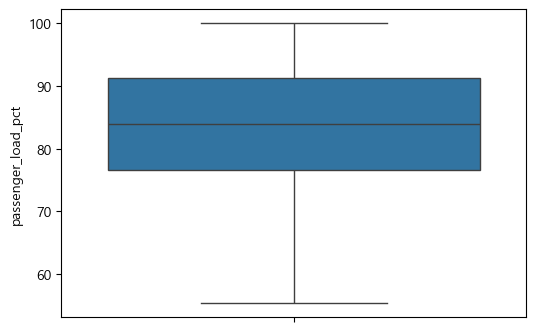

In [600]:
df = df[(df['passenger_load_pct'] <= 100)|(df['passenger_load_pct'].isna())]
df = df[(df['passenger_load_pct'] >= 55)|(df['passenger_load_pct'].isna())]
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['passenger_load_pct'])
plt.show()

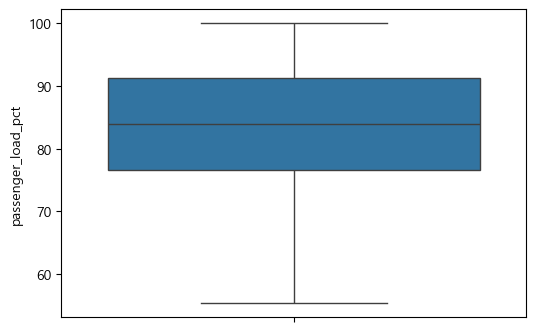

In [601]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['passenger_load_pct'])
plt.show()

In [602]:
df.dtypes

flight_id                     object
flight_date                   object
airline                       object
departure_airport             object
arrival_airport               object
scheduled_hour                 int64
day_of_week                    int64
distance_km                  float64
temperature_c                float64
wind_speed_kmh               float64
precipitation_mm             float64
visibility_km                float64
airport_congestion           float64
previous_flight_delay_min    float64
aircraft_age_years           float64
passenger_load_pct           float64
holiday                       object
weather_condition             object
delay_minutes                float64
dtype: object

In [603]:
df['airport_congestion'] = df.groupby(['departure_airport', 'scheduled_hour'])['airport_congestion'].transform(lambda x: x.fillna(x.median()))
df['airport_congestion'] = df['airport_congestion'].fillna(df['airport_congestion'].median())

df['aircraft_age_years'] = df.groupby('airline')['aircraft_age_years'].transform(lambda x: x.fillna(x.median()))
df['aircraft_age_years'] = df['aircraft_age_years'].fillna(df['aircraft_age_years'].median())
df['passenger_load_pct'] = df.groupby(['day_of_week', 'departure_airport', 'arrival_airport'])['passenger_load_pct'].transform(lambda x: x.fillna(x.median()))
df['passenger_load_pct'] = df['passenger_load_pct'].fillna(df['passenger_load_pct'].median())

df['previous_flight_delay_min'] = df['previous_flight_delay_min'].fillna(0)

In [604]:
for col in weather_num_cols:
    df[col] = df.groupby(['flight_date', 'departure_airport'])[col].transform(lambda x: x.fillna(x.median()))
    
    df[col] = df.groupby('departure_airport')[col].transform(lambda x: x.fillna(x.median()))
    
    if col == 'precipitation_mm':
        df[col] = df[col].fillna(0)
    else:
        df[col] = df[col].fillna(df[col].median())

def fill_mode(x):
    mode_val = x.mode()
    return x.fillna(mode_val[0]) if not mode_val.empty else x

df['weather_condition'] = df.groupby(['flight_date', 'departure_airport'])['weather_condition'].transform(fill_mode)

df['weather_condition'] = df['weather_condition'].fillna('Unknown')
df.isna().sum()

flight_id                    0
flight_date                  0
airline                      0
departure_airport            0
arrival_airport              0
scheduled_hour               0
day_of_week                  0
distance_km                  0
temperature_c                0
wind_speed_kmh               0
precipitation_mm             0
visibility_km                0
airport_congestion           0
previous_flight_delay_min    0
aircraft_age_years           0
passenger_load_pct           0
holiday                      0
weather_condition            0
delay_minutes                0
dtype: int64

In [605]:
df.head(0)

,flight_id,flight_date,airline,departure_airport,arrival_airport,scheduled_hour,day_of_week,distance_km,temperature_c,wind_speed_kmh,precipitation_mm,visibility_km,airport_congestion,previous_flight_delay_min,aircraft_age_years,passenger_load_pct,holiday,weather_condition,delay_minutes


In [606]:
df_new= df.copy()

In [607]:
df_new['date'] = pd.to_datetime(df_new['flight_date'], format='mixed')

# 2. 위에서 만든 df_new['date'] 컬럼에서 월 추출
df_new['month'] = df_new['date'].dt.month

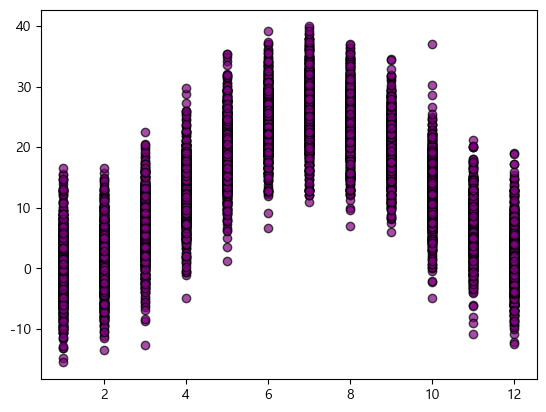

In [608]:
plt.scatter(df_new['month'], df_new['temperature_c'],  c='purple', alpha=0.7, edgecolors='black')
plt.show()
#일별로 쓰지말고 온도랑 휴일로 대체

In [609]:
top_airports = df['departure_airport'].value_counts().nlargest(10).index

df['departure_airport'] = df['departure_airport'].apply(lambda x: x if x in top_airports else 'Other')
df['arrival_airport'] = df['arrival_airport'].apply(lambda x: x if x in top_airports else 'Other')

In [610]:
df.head()

,flight_id,flight_date,airline,departure_airport,arrival_airport,scheduled_hour,day_of_week,distance_km,temperature_c,wind_speed_kmh,precipitation_mm,visibility_km,airport_congestion,previous_flight_delay_min,aircraft_age_years,passenger_load_pct,holiday,weather_condition,delay_minutes
0,FL202500768,2025/09/08,Jeju Air,pus,Other,16,0,406.4,12.20,16.5,0.0,12.4,0.572,14.3,12.7,72.0,0,Clear,24.9
1,FL202505880,2025-05-15,Asiana Airlines,KWJ,ICN,7,3,336.2,23.90,19.4,0.0,16.3,0.442,12.3,1.5,64.4,0,Clear,10.0
2,FL202508460,2025-02-25,Asiana Airlines,ICN,USN,20,1,366.8,0.35,3.2,0.0,5.4,0.502,2.1,3.7,88.2,0,Clear,1.0
3,FL202506025,2025-09-22,Jeju Air,KWJ,GMP,22,0,359.9,23.30,20.9,4.9,4.3,0.295,6.8,8.0,75.2,0,Rain,24.9
4,FL202501987,2025-04-21,Jin Air,ICN,USN,10,0,369.5,8.90,8.5,0.0,16.4,0.826,22.2,12.5,93.3,0,Clear,39.4


In [611]:
X = df.drop(columns=['flight_id','flight_date','delay_minutes'])
y = df['delay_minutes']

In [612]:
num_cols = X.select_dtypes(include=['number']).columns.tolist()

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
cat_cols

['airline',
 'departure_airport',
 'arrival_airport',
 'holiday',
 'weather_condition']

In [613]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, shuffle=True
)
print("Train 세트 크기:", X_train.shape)
print("Val   세트 크기:", X_val.shape)
print("Test  세트 크기:", X_test.shape)

Train 세트 크기: (5080, 16)
Val   세트 크기: (1694, 16)
Test  세트 크기: (1694, 16)


In [614]:
df.head()

,flight_id,flight_date,airline,departure_airport,arrival_airport,scheduled_hour,day_of_week,distance_km,temperature_c,wind_speed_kmh,precipitation_mm,visibility_km,airport_congestion,previous_flight_delay_min,aircraft_age_years,passenger_load_pct,holiday,weather_condition,delay_minutes
0,FL202500768,2025/09/08,Jeju Air,pus,Other,16,0,406.4,12.20,16.5,0.0,12.4,0.572,14.3,12.7,72.0,0,Clear,24.9
1,FL202505880,2025-05-15,Asiana Airlines,KWJ,ICN,7,3,336.2,23.90,19.4,0.0,16.3,0.442,12.3,1.5,64.4,0,Clear,10.0
2,FL202508460,2025-02-25,Asiana Airlines,ICN,USN,20,1,366.8,0.35,3.2,0.0,5.4,0.502,2.1,3.7,88.2,0,Clear,1.0
3,FL202506025,2025-09-22,Jeju Air,KWJ,GMP,22,0,359.9,23.30,20.9,4.9,4.3,0.295,6.8,8.0,75.2,0,Rain,24.9
4,FL202501987,2025-04-21,Jin Air,ICN,USN,10,0,369.5,8.90,8.5,0.0,16.4,0.826,22.2,12.5,93.3,0,Clear,39.4


In [615]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ],
    remainder='passthrough'
)

X_train = preprocessor.fit_transform(X_train)
X_val   = preprocessor.transform(X_val)
X_test  = preprocessor.transform(X_test)

In [616]:
X_train.shape

(5080, 49)

In [ ]:
#mae가 오차범위 ~분 사이라는 뜻
model = Sequential()
model.add(Dense(30,  input_dim=X_train.shape[1], activation='relu'))
model.add(Dense(12, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1))
model.summary()

#모델을 컴파일합니다.
model.compile(loss='mse', optimizer='adam', metrics=['mae'])

# 모델을 실행합니다.
history=model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val,y_val)) # 0.8 x 0.25 = 0.2
#mae값들이 줄어들었다가 다시 올라가는것이 확인되므로 과적합이 생기고있음을 알 수 있다.

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_53 (Dense)                │ (None, 30)             │         1,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 12)             │           372 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,985 (7.75 KB)

 Trainable params: 1,985 (7.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2309.1335 - mae: 33.8632 - val_loss: 2110.6433 - val_mae: 33.5404
Epoch 2/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1556.3945 - mae: 21.6412 - val_loss: 796.7164 - val_mae: 11.4874
Epoch 3/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 937.4244 - mae: 10.3361 - val_loss: 758.2222 - val_mae: 10.1508
Epoch 4/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 910.2929 - mae: 9.6016 - val_loss: 750.0131 - val_mae: 9.7650
Epoch 5/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 900.3676 - mae: 9.4190 - val_loss: 748.0073 - val_mae: 9.5808
Epoch 6/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 893.0570 - mae: 9.2773 - val_loss: 745.6335 - val_mae: 9.4685
Epoch 7/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 887.4650 - mae: 9.2504 - val_loss: 746.6684 - val_mae: 9.4270
Epoch 8/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 885.2717 - mae: 9.1255 - val_loss: 744.4362 - val_mae: 9.3994
Epoch 9/50
159/

In [618]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

val_pred = lasso.predict(X_val)
print("Lasso Val MAE:", mean_absolute_error(y_val, val_pred))

import numpy as np
used_features = np.sum(lasso.coef_ != 0)
print(f"전체 {X_train.shape[1]}개 중 선택된 특성 개수: {used_features}개")

Lasso Val MAE: 8.960088745198053
전체 49개 중 선택된 특성 개수: 32개


In [619]:
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l1

model = Sequential([
    # l1(0.01) 규제 추가로 불필요한 피처의 가중치를 0으로 억제
    Dense(64, input_dim=X_train.shape[1], activation='relu', kernel_regularizer=l1(0.01)),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_regularizer=l1(0.01)),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(loss='mse', optimizer='adam', metrics=['mae'])
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val))

Epoch 1/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1511.3235 - mae: 20.6840 - val_loss: 782.7599 - val_mae: 10.5720
Epoch 2/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 973.7993 - mae: 11.0220 - val_loss: 759.3558 - val_mae: 9.6605
Epoch 3/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 939.2254 - mae: 10.7498 - val_loss: 756.4866 - val_mae: 9.4851
Epoch 4/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 947.7399 - mae: 10.5793 - val_loss: 755.7916 - val_mae: 9.3891
Epoch 5/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 928.7855 - mae: 10.7005 - val_loss: 755.4561 - val_mae: 9.3916
Epoch 6/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 941.8752 - mae: 10.4615 - val_loss: 753.9333 - val_mae: 9.3323
Epoch 7/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 914.5626 - mae: 10.4280 - val_loss: 754.0684 - val_mae: 9.3279
Epoch 8/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 927.4455 - mae: 10.3695 - val_loss: 754.5087 - val_mae: 9.3548
Epoch 9/50
159

In [620]:
from tensorflow.keras.callbacks import ModelCheckpoint
# 모델 저장의 조건을 설정합니다.
modelpath = "./data/model/all/{epoch:02d}-{val_mae:.4f}.keras"
checkpointer = ModelCheckpoint(
    filepath=modelpath,
    monitor='val_mae',
    mode='min',
    save_best_only=True,
    verbose=1
)

# 모델을 실행합니다. 
history=model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.25, verbose=0, callbacks=[checkpointer])


Epoch 1: val_mae improved from None to 8.37401, saving model to ./data/model/all/01-8.3740.keras

Epoch 1: finished saving model to ./data/model/all/01-8.3740.keras

Epoch 2: val_mae did not improve from 8.37401

Epoch 3: val_mae did not improve from 8.37401

Epoch 4: val_mae did not improve from 8.37401

Epoch 5: val_mae did not improve from 8.37401

Epoch 6: val_mae did not improve from 8.37401

Epoch 7: val_mae did not improve from 8.37401

Epoch 8: val_mae did not improve from 8.37401

Epoch 9: val_mae did not improve from 8.37401

Epoch 10: val_mae did not improve from 8.37401

Epoch 11: val_mae did not improve from 8.37401

Epoch 12: val_mae did not improve from 8.37401

Epoch 13: val_mae did not improve from 8.37401

Epoch 14: val_mae did not improve from 8.37401

Epoch 15: val_mae did not improve from 8.37401

Epoch 16: val_mae did not improve from 8.37401

Epoch 17: val_mae did not improve from 8.37401

Epoch 18: val_mae did not improve from 8.37401

Epoch 19: val_mae did not

In [621]:
score=model.evaluate(X_test, y_test)
print('Test loss:', score[1])

53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - loss: 553.1890 - mae: 9.4082
Test loss: 9.408202171325684


In [622]:
# 그래프 확인을 위한 긴 학습 (컴퓨터 환경에 따라 시간이 다소 걸릴수 있습니다)
history=model.fit(X_train, y_train, epochs=2000, batch_size=32, verbose=0, validation_data=(X_val,y_val)) 

In [623]:
# history에 저장된 학습 결과를 확인해 보겠습니다. 
hist_df=pd.DataFrame(history.history)
hist_df

,loss,mae,val_loss,val_mae
0,409.683258,9.705664,945.839905,10.318375
1,291.999817,9.395269,884.778320,10.062815
2,362.452820,9.540769,860.860840,10.052738
3,341.095520,9.449461,961.413940,10.554720
4,418.735291,9.658373,876.415649,10.185195
...,...,...,...,...
1995,97.237961,6.710794,940.844971,10.674235
1996,158.666641,6.843938,990.691833,10.981406
1997,158.238281,6.954630,1013.562256,11.178695
1998,116.028214,6.659975,956.274109,10.946414


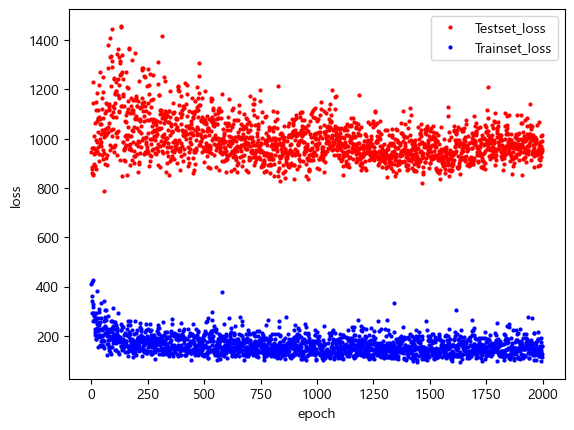

In [624]:
# y_vloss에 테스트셋(여기서는 검증셋)의 오차를 저장합니다.
y_vloss=hist_df['val_loss']

# y_loss에 학습셋의 오차를 저장합니다.
y_loss=hist_df['loss']

# x 값을 지정하고 테스트셋(검증셋)의 오차를 빨간색으로, 학습셋의 오차를 파란색으로 표시합니다.
x_len = np.arange(len(y_loss))
plt.plot(x_len, y_vloss, "o", c="red", markersize=2, label='Testset_loss')
plt.plot(x_len, y_loss, "o", c="blue", markersize=2, label='Trainset_loss')

plt.legend(loc='upper right')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

In [625]:
# 그래프 확인을 위한 긴 학습 (컴퓨터 환경에 따라 시간이 다소 걸릴수 있습니다)
history=model.fit(X_train, y_train, epochs=500, batch_size=32, verbose=0, validation_data=(X_val,y_val))  

In [626]:
# history에 저장된 학습 결과를 확인해 보겠습니다. 
hist_df=pd.DataFrame(history.history)
hist_df

,loss,mae,val_loss,val_mae
0,152.910065,6.934778,943.456116,10.764619
1,181.042709,6.890468,944.635925,10.676444
2,150.630890,6.928712,992.928345,10.814767
3,111.363045,6.708544,989.658752,10.810616
4,152.188858,6.901899,905.556580,10.703943
...,...,...,...,...
495,147.842697,6.814593,1012.016663,11.212074
496,131.951752,6.812794,982.570679,10.984947
497,145.117050,6.900201,1042.128662,11.339906
498,202.455383,7.046195,913.106995,10.750556


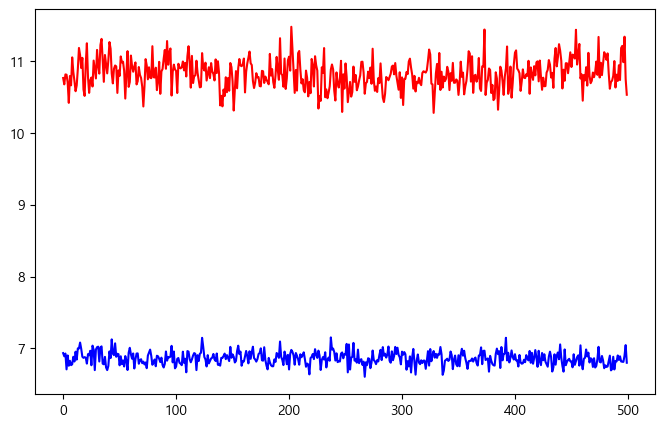

In [627]:
y_vmae = hist_df['val_mae']
y_mae = hist_df['mae']

x_len = np.arange(len(y_mae))

plt.figure(figsize=(8, 5))
plt.plot(x_len, y_vmae, c="red", label='Validation MAE')
plt.plot(x_len, y_mae, c="blue", label='Train MAE')

plt.show()

In [628]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
# 학습이 언제 자동 중단 될지를 설정합니다.
early_stopping_callback = EarlyStopping(monitor='val_mae', patience=20, restore_best_weights=True)

#최적화 모델이 저장될 폴더와 모델의 이름을 정합니다.
modelpath="./data/model/Ch14-4-bestmodel.keras"

# 최적화 모델을 업데이트하고 저장합니다.
checkpointer = ModelCheckpoint(filepath=modelpath, monitor='val_mae', verbose=0, save_best_only=True)

#모델을 실행합니다.
history=model.fit(X_train, y_train, epochs=2000, batch_size=32, validation_data=(X_val,y_val), verbose=1, callbacks=[early_stopping_callback,checkpointer]) 

Epoch 1/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 149.1262 - mae: 6.8565 - val_loss: 946.1160 - val_mae: 10.8150
Epoch 2/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 170.4973 - mae: 6.9344 - val_loss: 930.6763 - val_mae: 10.9471
Epoch 3/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 123.2225 - mae: 6.8003 - val_loss: 921.8004 - val_mae: 10.8906
Epoch 4/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 142.7364 - mae: 6.8096 - val_loss: 886.1048 - val_mae: 10.6814
Epoch 5/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 142.2559 - mae: 6.8288 - val_loss: 925.5379 - val_mae: 10.7792
Epoch 6/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 101.3676 - mae: 6.6392 - val_loss: 982.8512 - val_mae: 10.9544
Epoch 7/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 148.0240 - mae: 6.7536 - val_loss: 899.1970 - val_mae: 10.7272
Epoch 8/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 126.7854 - mae: 6.7445 - val_loss: 957.0237 - val_mae: 11.0126


In [629]:
# history에 저장된 학습 결과를 확인해 보겠습니다. 
hist_df=pd.DataFrame(history.history)

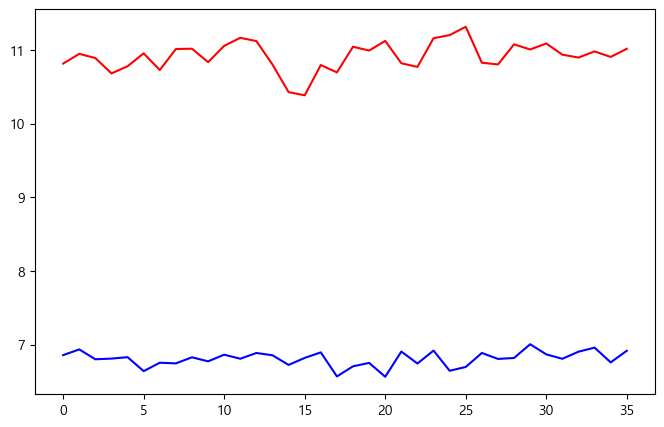

In [630]:
y_vmae = hist_df['val_mae']
y_mae = hist_df['mae']

x_len = np.arange(len(y_mae))

plt.figure(figsize=(8, 5))
plt.plot(x_len, y_vmae, c="red", label='Validation MAE')
plt.plot(x_len, y_mae, c="blue", label='Train MAE')

plt.show()

In [631]:
# 테스트 결과를 출력합니다.
from tensorflow.keras.models import load_model
best_model = load_model("./data/model/Ch14-4-bestmodel.keras")
score = best_model.evaluate(X_test, y_test)
print('Test mae:', score[1])

53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 596.9092 - mae: 9.7812 
Test mae: 9.781227111816406


In [632]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
import tensorflow as tf
model.compile(
    loss='mse',
    optimizer='adam',
    metrics=['mae', tf.keras.metrics.RootMeanSquaredError(name='rmse')]
)
# 학습이 언제 자동 중단 될지를 설정합니다.
early_stopping_callback = EarlyStopping(monitor='val_rmse', patience=20, restore_best_weights=True)

#최적화 모델이 저장될 폴더와 모델의 이름을 정합니다.
modelpath="./data/model/Ch14-4-bestmodel.keras"

# 최적화 모델을 업데이트하고 저장합니다.
checkpointer = ModelCheckpoint(filepath=modelpath, monitor='val_rmse', verbose=0, save_best_only=True)

#모델을 실행합니다.
history=model.fit(X_train, y_train, epochs=2000, batch_size=32, validation_data=(X_val,y_val), verbose=1, callbacks=[early_stopping_callback,checkpointer]) 

Epoch 1/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 143.4421 - mae: 6.9135 - rmse: 11.3767 - val_loss: 893.1874 - val_mae: 10.7275 - val_rmse: 29.6586
Epoch 2/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 218.1369 - mae: 7.1191 - rmse: 14.3068 - val_loss: 934.6204 - val_mae: 10.9473 - val_rmse: 30.3521
Epoch 3/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 141.1972 - mae: 6.9423 - rmse: 11.3095 - val_loss: 945.8168 - val_mae: 10.8545 - val_rmse: 30.5372
Epoch 4/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 170.3481 - mae: 7.0388 - rmse: 12.5321 - val_loss: 956.5967 - val_mae: 11.0207 - val_rmse: 30.7133
Epoch 5/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 136.3830 - mae: 6.9205 - rmse: 11.0940 - val_loss: 944.8091 - val_mae: 10.7458 - val_rmse: 30.5202
Epoch 6/2000
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 118.3524 - mae: 6.9251 - rmse: 10.2473 - val_loss: 931.3248 - val_mae: 10.7172 - val_rmse: 30.2981
Epoch 7/2000
159/159 ━━━━━━━━━━━━━

In [634]:
# 테스트 결과를 출력합니다.
from tensorflow.keras.models import load_model
best_model = load_model("./data/model/Ch14-4-bestmodel.keras")
score = best_model.evaluate(X_test, y_test)
print('Test rmse:', score[2])
print('Test mae:', score[1])
print('Test LOSS:', score[0])

53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step - loss: 561.8967 - mae: 9.7898 - rmse: 23.4167 
Test rmse: 23.416656494140625
Test mae: 9.789836883544922
Test LOSS: 561.8966674804688
